## Disordered hexagon to uniform symmetric hexagon with pure mechanics ##

- Using Area, perimeter, line tension effectors
- Euler dynamic solver
- modified the plot fucntion and broken the solver steps to chunks 

In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image


from tyssue import config, Sheet, SheetGeometry, History, EventManager
from tyssue.draw import sheet_view
from tyssue.generation import three_faces_sheet
from tyssue.draw.plt_draw import plot_forces

from tyssue.dynamics import PlanarModel

from tyssue.solvers.viscous import EulerSolver
from tyssue.draw.plt_draw import create_gif


import numpy as np
from tyssue.config.geometry import flat_sheet
from tyssue import Sheet, Monolayer, config, SheetGeometry
import pandas as pd

In [120]:
def one_face_sheet_array():

    Nc = 1
    
    points = np.array(

        # [
        #     [2,8],
        #     [5,8],
        #     [4,7],
        #     [5,6],
        #     [2,6],
        #     [3,7],
        
        # ] )
        # [
        # [2.0, 8.0],   # Vertex 0
        # [5.0, 8.0],   # Vertex 1
        # [4.0, 7.0],   # Vertex 2: inward indentation
        # [5.0, 6.0],   # Vertex 3
        # [2.0, 6.0],   # Vertex 4
        # [3.0, 7.0],   # Vertex 5: inward indentation

        [
            [3,9],
            [6,12],
            [10,10],
            [10,6],
            [6.05, 2.2],
            [2.5, 6],
        
        ] )
  


    edges = np.array(

        [
            [0, 1],
            [1, 2],
            [2, 3],
            [3, 4], 
            [4, 5], 
            [5, 0],

        ] )

    Nv, Ne = len(points), len(edges)
    return points, edges, (Nc, Nv, Ne)

In [122]:
from tyssue.generation.utils import make_df

def one_face_sheet(zaxis = False):

    points, _, (Nc, Nv, Ne) = one_face_sheet_array()

    if zaxis:
        coords = ['x', 'y', 'z']

    else:

        coords = ['x', 'y']


    face_idx = pd.Index([0], name='face')
    vert_idx = pd.Index(range(Nv), name="vert")


    _edge_e_idx = np.array(
        [
            [0, 1, 0],
            [1, 2, 0],
            [2, 3, 0],
            [3, 4, 0],
            [4, 5, 0],
            [5, 0, 0],
            
            
        ]
    )

    edge_idx = pd.Index(range(_edge_e_idx.shape[0]), name="edge")

    specifications = flat_sheet()

    
    ## Faces DataFrame
    face_df = make_df(index=face_idx, spec=specifications["face"])
    
    ## Junction vertices and edges DataFrames
    vert_df = make_df(index=vert_idx, spec=specifications["vert"])
    edge_df = make_df(index=edge_idx, spec=specifications["edge"])


    # Junction vertices and edge dataframe
    edge_df["srce"] = _edge_e_idx[:, 0]
    edge_df["trgt"] = _edge_e_idx[:, 1]
    edge_df["face"] = _edge_e_idx[:, 2]


    vert_df.loc[:, coords[:2]] = points
    if zaxis:
        vert_df.loc[:, coords[2:]] = 0.0


    

    datasets = {"face": face_df, "vert": vert_df, "edge": edge_df}
    return datasets, specifications

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_171115_270244.png


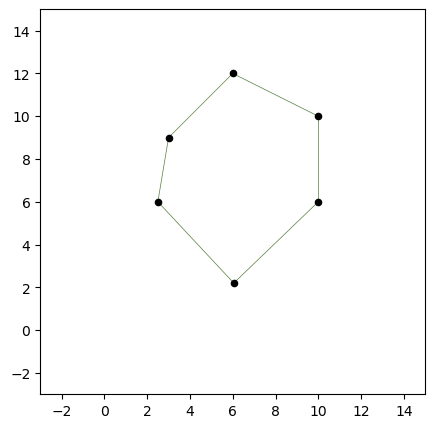

In [124]:
from tyssue.draw import sheet_view 



sheet = Sheet('1f', *one_face_sheet())



geom = SheetGeometry

geom.update_all(sheet)

fig, ax = sheet_view(sheet, xlim=(-5,20), ylim=(-5,20), figsize=(5,5))

ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)
fig.set_size_inches(5, 5)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_171116_559203.png


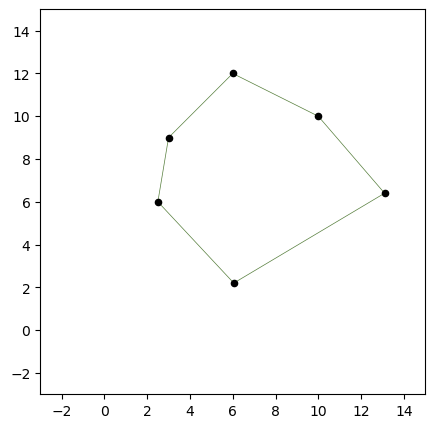

In [126]:
vertex_id = int(boundary.iloc[3])

sheet.vert_df.loc[vertex_id, "x"] += 3.1
sheet.vert_df.loc[vertex_id, "y"] += 0.4

geom.update_all(sheet)

fig, ax = sheet_view(sheet, xlim=(-5,20), ylim=(-5,20), figsize=(5,5))

ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)
fig.set_size_inches(5, 5)

In [128]:
# Get vertex coordinates
vertices = sheet.vert_df  # bu this we can get the vertices coords and store it in vertices

display(vertices)


,x,y,z,is_active,rho,height,basal_shift
vert,,,,,,,
0,3.00,9.0,0.0,1,0.0,-4.0,4.0
1,6.00,12.0,0.0,1,0.0,-4.0,4.0
2,10.00,10.0,0.0,1,0.0,-4.0,4.0
3,13.10,6.4,0.0,1,0.0,-4.0,4.0
4,6.05,2.2,0.0,1,0.0,-4.0,4.0
5,2.50,6.0,0.0,1,0.0,-4.0,4.0


In [130]:
print(sheet.vert_df[["x", "y"]]);
print(sheet.face_df[["area", "num_sides"]])

          x     y
vert             
0      3.00   9.0
1      6.00  12.0
2     10.00  10.0
3     13.10   6.4
4      6.05   2.2
5      2.50   6.0
      area  num_sides
face                 
0     59.8          6


In [132]:
sheet.face_df

,x,y,z,num_sides,area,perimeter,is_alive,id,height,rho,vol
face,,,,,,,,,,,
0,6.775,7.6,0.0,6,59.8,29.913435,1,0,-4.0,0.0,-239.2


In [134]:
def hexagon_area(points):
    x = points[:, 0]
    y = points[:, 1]

    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def hexagon_perimeter(points):

    x = points[:, 0]
    y = points[:, 1]

    # dx = np.roll(x, -1) - x
    # dy = np.roll(y, -1) - y

    # edge_lengths = np.sqrt(dx**2 + dy**2)

    # return np.sum(edge_lengths)
    
    
    
    # Euler distance #
    return np.sum(np.sqrt((np.roll(x, -1) - x)**2 + (np.roll(y, -1) - y)**2))  

In [136]:
points = np.array([

            # [4,10],
            # [6.598, 8.5],
            # [6.598, 5.5],
            # [4, 4],
            # [1.402, 5.5],
            # [1.402, 8.5],
        
            # [2.0, 8.0],   # Vertex 0
            # [5.0, 8.0],   # Vertex 1
            # [4.0, 7.0],   # Vertex 2: inward indentation
            # [5.0, 6.0],   # Vertex 3
            # [2.0, 6.0],   # Vertex 4
            # [3.0, 7.0],  
            [3,9],
            [6,12],
            [10,10],
            [10,6],
            [6.05, 2.2],
            [2.5, 6],
    
])

print(f"Area of the irregular hexagon: {hexagon_area(points)}")
print(f"Perimeter of the irregular hexagon: {hexagon_perimeter(points)}")

Area of the irregular hexagon: 48.5
Perimeter of the irregular hexagon: 26.437502189739543


In [138]:
valid_faces = sheet.face_df.index[sheet.face_df["area"] > 1e-12] # condition for a valid face

face_id = valid_faces[0]
# For this face, get its boundary's edge IDs and source vertex IDs
boundary = sheet.get_orbits("face", "srce").loc[face_id]

print("Face:", face_id) # print face id
print("Boundary edge IDs:", list(boundary.index)) # print edge id 
print("Boundary vertex IDs:", list(boundary.values)) # print vertex id

print(sheet.edge_df.loc[boundary.index, ["srce", "trgt", "length"]]) #calculating length by Euler distance           
print(sheet.vert_df.loc[boundary.values, ["x", "y"]])

Face: 0
Boundary edge IDs: [0, 1, 2, 3, 4, 5]
Boundary vertex IDs: [0, 1, 2, 3, 4, 5]
      srce  trgt    length
edge                      
0        0     1  4.242641
1        1     2  4.472136
2        2     3  4.750789
3        3     4  8.206248
4        4     5  5.200240
5        5     0  3.041381
          x     y
vert             
0      3.00   9.0
1      6.00  12.0
2     10.00  10.0
3     13.10   6.4
4      6.05   2.2
5      2.50   6.0


In [140]:
print(sheet.face_df.loc[face_id, ["area", "perimeter", "num_sides"]])
print(sheet.edge_df.loc[boundary.index, "length"].sum())

area         59.800000
perimeter    29.913435
num_sides     6.000000
Name: 0, dtype: float64
29.913435314369227


In [142]:
print(sheet.face_df.loc[face_id, ["area", "perimeter", "num_sides"]])
print(sheet.edge_df.loc[boundary.index, "length"].sum())

area         59.800000
perimeter    29.913435
num_sides     6.000000
Name: 0, dtype: float64
29.913435314369227


In [144]:
vertex_ids = boundary.values # boundary.values gives the vertex IDs, and ["x", "y"] selects their coordinate
coordinates = sheet.vert_df.loc[vertex_ids, ["x", "y"]] # .loc[rows, columns]
display(coordinates)

,x,y
vert,,
0,3.00,9.0
1,6.00,12.0
2,10.00,10.0
3,13.10,6.4
4,6.05,2.2
5,2.50,6.0


In [148]:
from tyssue.dynamics import effectors, model_factory

area_model = model_factory([
    effectors.FaceAreaElasticity,
    effectors.LineTension
    # effectors.PerimeterElasticity
])

sheet.update_specs(area_model.specs, reset=True)

# Area energy parameters
sheet.face_df["area_elasticity"] = 1.0
sheet.face_df["prefered_area"] = 62.0

target_area = sheet.face_df["prefered_area"].iloc[0]

# line tension affector value
sheet.edge_df["LineTension"] = 4.0

# # Perimeter energy parameters
# sheet.face_df["perimeter_elasticity"] = 1.0
# # sheet.face_df["prefered_perimeter"] = 6 * np.sqrt(4 * target_area/ (3 * np.sqrt(3)))
# sheet.face_df["prefered_perimeter"] = 15.0 # this gives a regular hexagon shape 


geom.update_all(sheet)
print(target_area)

Reseting column is_alive of the face dataset with new specs
Reseting column area of the face dataset with new specs
Reseting column area_elasticity of the face dataset with new specs
Reseting column prefered_area of the face dataset with new specs
Reseting column sub_area of the edge dataset with new specs
Reseting column is_active of the edge dataset with new specs
Reseting column line_tension of the edge dataset with new specs


62.0


In [150]:
grad = area_model.compute_gradient(sheet)

g = grad.loc[sheet.active_verts, ["gx", "gy"]].to_numpy()
force_magnitudes = np.linalg.norm(g, axis=1)


print("Gradient magnitude at each vertex:", force_magnitudes)
print("Maximum gradient magnitude:", force_magnitudes.max())

Gradient magnitude at each vertex: [11.28181649 10.92559559 16.17565743 14.34024425 15.49862935 10.9506313 ]
Maximum gradient magnitude: 16.175657427587367


In [152]:
import numpy as np

grad_E = area_model.compute_gradient(sheet)

grad_E["magnitude"] = np.sqrt(grad_E["gx"]**2 + grad_E["gy"]**2 + grad_E["gz"]**2)

print(grad_E[["gx", "gy", "gz", "magnitude"]])

area_model.specs

             gx         gy   gz  magnitude
srce                                      
0     10.815093  -3.211410  0.0  11.281816
1      3.199126 -10.446733  0.0  10.925596
2     -7.685310 -14.233338  0.0  16.175657
3    -13.334637   5.275421  0.0  14.340244
4     -1.946890  15.375862  0.0  15.498629
5      8.514271   6.886474  0.0  10.950631


{'cell': {},
 'face': {'is_alive': 1,
  'area': 1.0,
  'area_elasticity': 1.0,
  'prefered_area': 1.0},
 'edge': {'sub_area': 0.16666666666666666,
  'is_active': 1,
  'line_tension': 1.0},
 'vert': {},
 'settings': {'nrj_norm_factor': 1.0}}

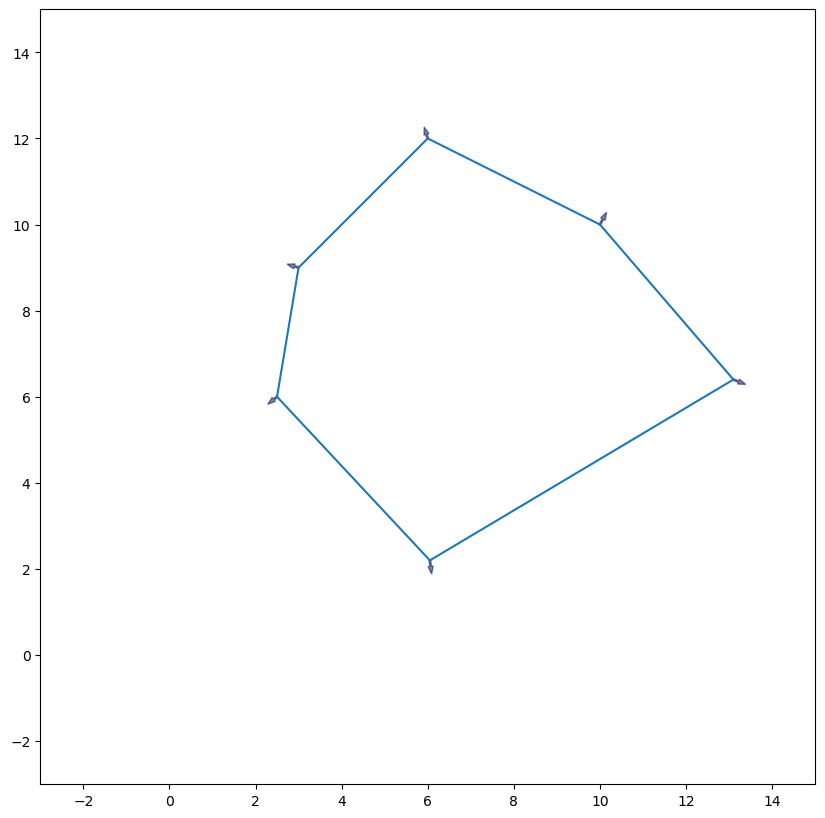

In [154]:
from tyssue.draw.plt_draw import plot_forces


fig, ax = plot_forces(sheet, geom, area_model, ['x', 'y'], scaling=0.009)
ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)

fig.set_size_inches(10, 12)

In [156]:
sheet.update_specs(area_model.specs, reset=True)

# Target area
sheet.face_df["area_elasticity"] = 1.0
sheet.face_df["prefered_area"] = 62.0

target_area = sheet.face_df["prefered_area"].iloc[0]

# line tension affector value
sheet.edge_df["LineTension"] = 4.0

# # Perimeter energy parameters
# sheet.face_df["perimeter_elasticity"] = 1.0
# # sheet.face_df["prefered_perimeter"] = 6 * np.sqrt(4 * target_area/ (3 * np.sqrt(3)))
# sheet.face_df["prefered_perimeter"] = 15.0 # this gives a regular hexagon shape 


geom.update_all(sheet)

print("Target area:", target_area)
# print("Target perimeter:", target_perimeter)

Reseting column is_alive of the face dataset with new specs
Reseting column area of the face dataset with new specs
Reseting column area_elasticity of the face dataset with new specs
Reseting column prefered_area of the face dataset with new specs
Reseting column sub_area of the edge dataset with new specs
Reseting column is_active of the edge dataset with new specs
Reseting column line_tension of the edge dataset with new specs


Target area: 62.0


In [158]:
# Assign viscosity to every vertex
sheet.vert_df["viscosity"] = 10.0

from tyssue.solvers.viscous import EulerSolver


solver = EulerSolver(sheet, geom, area_model)

In [160]:
import numpy as np
import time
from tyssue.solvers.viscous import EulerSolver

# sheet.vert_df["viscosity"] = 10.0
# solver = EulerSolver(sheet, geom, area_model)

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

dt = 0.01
chunk_steps = 20
max_chunks = 1000
tolerance = 1e-4

start = time.perf_counter()

for chunk in range(max_chunks):
    # Advance the model by a chunk of time
    tf = (chunk + 1) * chunk_steps * dt
    solver.solve(tf=tf, dt=dt)

    grad = area_model.compute_gradient(sheet)
    grad_active = grad.loc[
        sheet.active_verts, ["gx", "gy"]
    ].to_numpy()

    if not np.isfinite(grad_active).all():
        print("Simulation became numerically unstable.")
        break

    max_gradient = np.linalg.norm(grad_active, axis=1).max()

    if chunk % 10 == 0:
        print(
            f"Chunk {chunk}: "
            f"max gradient = {max_gradient:.3e}"
        )

    if max_gradient < tolerance:
        print(f"Converged after {chunk + 1} chunks.")
        break

print(f"Elapsed time: {time.perf_counter() - start:.2f} seconds")



# import numpy as np

# dt = 0.0001
# max_steps = 10000
# tolerance = 1e-2

# for step in range(max_steps):
#     grad = area_model.compute_gradient(sheet)

#     grad_active = grad.loc[
#         sheet.active_verts, ["gx", "gy"]
#     ].to_numpy()

#     if not np.isfinite(grad_active).all():
#         print("Simulation became numerically unstable.")
#         break

#     max_force = np.linalg.norm(grad_active, axis=1).max()

#     if max_force < tolerance:
#         print(f"Equilibrium reached at step {step}")
#         print(f"Maximum gradient magnitude: {max_force:.3e}")
#         break

#     solver.solve(tf=(step + 1) * dt, dt=dt)

# else:
#     print("Maximum steps reached before equilibrium.")

Chunk 0: max gradient = 9.394e-01
Chunk 10: max gradient = 5.779e-01
Chunk 20: max gradient = 5.377e-01
Chunk 30: max gradient = 5.175e-01
Chunk 40: max gradient = 5.021e-01
Chunk 50: max gradient = 4.884e-01
Chunk 60: max gradient = 4.762e-01
Chunk 70: max gradient = 4.652e-01
Chunk 80: max gradient = 4.554e-01
Chunk 90: max gradient = 4.465e-01
Chunk 100: max gradient = 4.385e-01
Chunk 110: max gradient = 4.312e-01
Chunk 120: max gradient = 4.246e-01
Chunk 130: max gradient = 4.185e-01
Chunk 140: max gradient = 4.129e-01
Chunk 150: max gradient = 4.077e-01
Chunk 160: max gradient = 4.029e-01
Chunk 170: max gradient = 3.984e-01
Chunk 180: max gradient = 3.942e-01
Chunk 190: max gradient = 3.903e-01
Chunk 200: max gradient = 3.866e-01
Chunk 210: max gradient = 3.831e-01
Chunk 220: max gradient = 3.797e-01
Chunk 230: max gradient = 3.766e-01
Chunk 240: max gradient = 3.736e-01
Chunk 250: max gradient = 3.707e-01
Chunk 260: max gradient = 3.679e-01
Chunk 270: max gradient = 3.653e-01
Chu

In [162]:
print(sheet.face_df.loc[face_id, ["area", "perimeter", "num_sides"]])
print(sheet.edge_df.loc[boundary.index, "length"].sum())

area         61.881667
perimeter    29.293587
num_sides     6.000000
Name: 0, dtype: float64
29.293587290245608


In [164]:
grad_E = area_model.compute_gradient(sheet)

grad_E["magnitude"] = np.sqrt(grad_E["gx"]**2 + grad_E["gy"]**2 + grad_E["gz"]**2)

print(grad_E[["gx", "gy", "gz", "magnitude"]])

            gx        gy   gz  magnitude
srce                                    
0    -0.299435  0.009238  0.0   0.299578
1    -0.152084  0.257159  0.0   0.298765
2     0.157027  0.251018  0.0   0.296087
3     0.291662 -0.038013  0.0   0.294128
4     0.080216 -0.258928  0.0   0.271069
5    -0.174228 -0.213662  0.0   0.275694


In [166]:
create_gif(solver.history, "sheet3.gif", num_frames=500)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173721_841041.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173722_076643.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173722_263173.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173722_470867.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173722_681882.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173722_911620.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173723_120898.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173723_347412.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173723_572465.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173723_809756.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173724_118679.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173724_313881.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261101_173724_520334.png
Plot saved: C:\Users\Arya

'C:\\Users\\Aryan\\tyssue Simulations\\sheet3.gif'

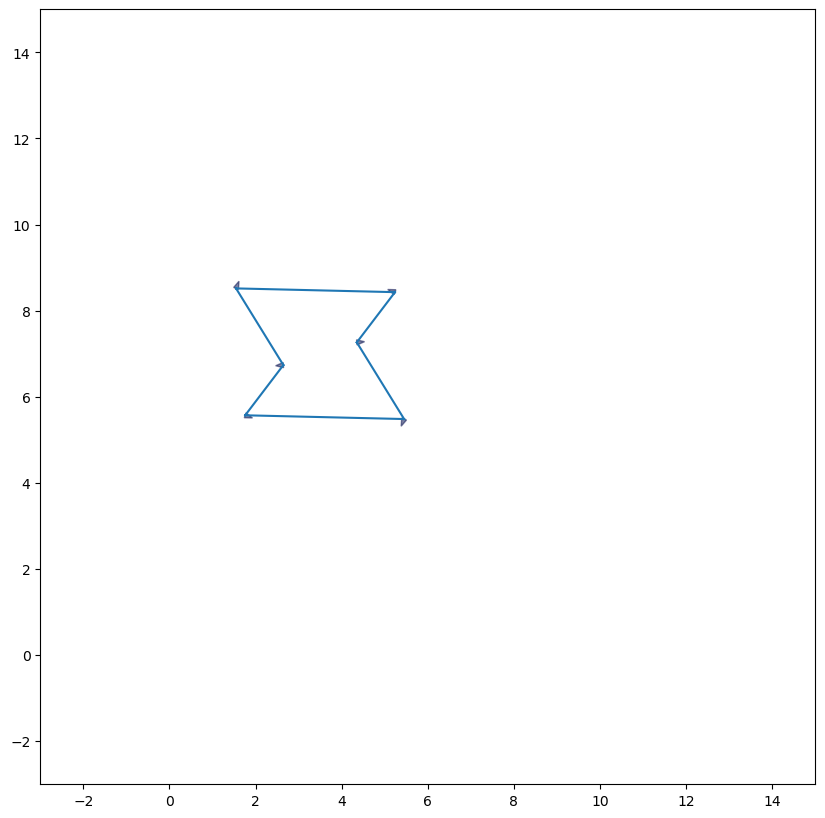

In [48]:
fig, ax = plot_forces(sheet, geom, area_model, ['x', 'y'], scaling=0.009)
ax.set_xlim(-3, 15)
ax.set_ylim(-3, 15)

fig.set_size_inches(10, 12)